<a href="https://www.kaggle.com/code/nicapotato/solid-state-ev-cells?scriptVersionId=364866950" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Telemetry Exploration — Solid-State EV Cells
_Cycle count tracks state of health; chemistry labels do not_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [luthfimuthathohirin/solid-state-ev-battery-telemetry-2026](https://www.kaggle.com/datasets/luthfimuthathohirin/solid-state-ev-battery-telemetry-2026)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Chemistry, Readiness, and Duty](#Chemistry)** <br>
**5. [Degradation Labels](#Tiers)** <br>
**6. [Correlations](#Correlations)** <br>
**7. [What Tracks State of Health](#Model)** <br>
**8. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one cell: 10,000 cells, 29 fields, no missing values. `cell_id` is unique. The free-text rationale is also unique per cell, so it is a note, not a category.

State of health (`state_of_health_pct`) runs from 70 to 100, with median 86.7. Cycle count has median 1,256. The question is whether chemistry and the named application move health once cycle count, resistance, charge rate, and temperature are on the table.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import json
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` tests a crosstab and rank correlations; `sklearn` fits one linear model on a hold-out split. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
CSV_BASENAME = "solid_state_ev_battery_telemetry_enriched_2026.csv"
KAGGLE_SLUG = "luthfimuthathohirin/solid-state-ev-battery-telemetry-2026"
TIER_ORDER = [
    "Minimal_Degradation_Tier_1",
    "Moderate_Degradation_Tier_2",
    "Accelerated_Degradation_Tier_3",
    "Critical_Thermal_Risk_Tier_4",
]
TRL_ORDER = [
    "TRL_6_Laboratory_Prototype",
    "TRL_7_Automotive_Testing",
    "TRL_8_Pilot_Production",
    "TRL_9_Commercial_Fleet",
]
EXPECTED = [
    "cell_id", "manufacturer", "electrolyte_chemistry", "anode_composition",
    "cathode_chemistry", "nominal_capacity_ah", "gravimetric_energy_density_wh_kg",
    "volumetric_energy_density_wh_l", "cycle_number", "charging_c_rate",
    "discharging_c_rate", "operating_temperature_c", "ambient_temperature_c",
    "internal_resistance_mohm", "state_of_health_pct", "coulombic_efficiency_pct",
    "stack_pressure_mpa", "dendrite_penetration_risk", "thermal_runaway_onset_c",
    "nominal_voltage_plateau_v", "target_ev_application", "thermal_stability_margin_c",
    "fast_charge_acceptance_score", "dendrite_mitigation_efficiency",
    "projected_cycle_life_80pct_soh", "commercial_readiness_level",
    "degradation_risk_tier", "cot_electrochemical_risk_rationale", "confidence_score",
]


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        hits = sorted(kaggle_root.rglob(basename))
        assert hits, f"no {basename} under {kaggle_root}"
        return hits[0]
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(slug))
    hits = sorted(root.rglob(basename))
    assert hits, f"expected {basename} under {root}"
    return hits[0]


csv_path = resolve_file(CSV_BASENAME)
print("CSV:", csv_path)
df = pd.read_csv(csv_path, low_memory=False)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (10000, 29), df.shape
assert int(df.isnull().sum().sum()) == 0
assert df["cell_id"].nunique() == 10000
assert df["cot_electrochemical_risk_rationale"].nunique() == 10000
df["degradation_risk_tier"] = pd.Categorical(df["degradation_risk_tier"], TIER_ORDER, ordered=True)
df["commercial_readiness_level"] = pd.Categorical(
    df["commercial_readiness_level"], TRL_ORDER, ordered=True
)

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print("Manufacturers:", df["manufacturer"].nunique(), "| Applications:", df["target_ev_application"].nunique())
print(
    f"SOH median {df['state_of_health_pct'].median():.2f} "
    f"(min {df['state_of_health_pct'].min():.1f}, max {df['state_of_health_pct'].max():.1f})"
)
print(f"Cycle median {df['cycle_number'].median():.0f}")
display(df.dtypes.to_frame("dtype"))
display(df.drop(columns=["cot_electrochemical_risk_rationale"]).sample(5, random_state=7))

CSV: /kaggle/input/datasets/luthfimuthathohirin/solid-state-ev-battery-telemetry-2026/solid_state_ev_battery_telemetry_enriched_2026.csv
Dataframe Dimension: 10000 Rows, 29 Columns
Manufacturers: 9 | Applications: 5
SOH median 86.67 (min 70.0, max 100.0)
Cycle median 1256


,dtype
cell_id,object
manufacturer,object
electrolyte_chemistry,object
anode_composition,object
cathode_chemistry,object
nominal_capacity_ah,float64
gravimetric_energy_density_wh_kg,float64
volumetric_energy_density_wh_l,float64
cycle_number,int64
charging_c_rate,float64


,cell_id,manufacturer,electrolyte_chemistry,anode_composition,cathode_chemistry,nominal_capacity_ah,gravimetric_energy_density_wh_kg,volumetric_energy_density_wh_l,cycle_number,charging_c_rate,discharging_c_rate,operating_temperature_c,ambient_temperature_c,internal_resistance_mohm,state_of_health_pct,coulombic_efficiency_pct,stack_pressure_mpa,dendrite_penetration_risk,thermal_runaway_onset_c,nominal_voltage_plateau_v,target_ev_application,thermal_stability_margin_c,fast_charge_acceptance_score,dendrite_mitigation_efficiency,projected_cycle_life_80pct_soh,commercial_readiness_level,degradation_risk_tier,confidence_score
1977,BAT-CATL-34A31EF8,CATL,Polymer_Composite,Graphite_Silicon_Composite,High_Nickel_NMC811,101.5,414.7,912.8,871,2.3,1.1,45.6,36.5,6.32,91.67,99.626,2.90,0.155,208,3.64,Commercial_Class8_Hauler,162.4,49.21,32.37,2091,TRL_8_Pilot_Production,Critical_Thermal_Risk_Tier_4,0.952
3880,BAT-PANA-4965CCF3,Panasonic Energy,Oxide_Based_LLZO,Silicon_Dominant_Nanowire,High_Nickel_NMC811,49.9,416.1,898.5,1639,8.6,3.7,75.0,48.1,13.42,73.83,98.975,4.77,0.376,347,3.78,Hypercar_Track,272.0,71.63,29.75,1253,TRL_8_Pilot_Production,Critical_Thermal_Risk_Tier_4,0.946
52,BAT-BYD-2CE1A6B6,BYD,Halide_Based_Li3YCl6,Silicon_Dominant_Nanowire,High_Nickel_NMC811,107.1,406.0,900.2,1260,2.9,1.7,49.4,37.0,8.17,87.67,99.375,2.43,0.216,311,3.63,Commercial_Class8_Hauler,261.6,59.18,22.27,2044,TRL_8_Pilot_Production,Moderate_Degradation_Tier_2,0.949
2551,BAT-CATL-098601F1,CATL,Sulfide_Based_Li10GeP2S12,Silicon_Dominant_Nanowire,LFP_Advanced,67.2,389.3,859.2,1117,3.0,1.8,51.9,40.0,7.80,88.13,99.650,3.36,0.177,274,3.23,Urban_Compact_SUV,222.1,64.70,34.77,1882,TRL_6_Laboratory_Prototype,Moderate_Degradation_Tier_2,0.958
2246,BAT-CATL-95ACB378,CATL,Polymer_Composite,Silicon_Dominant_Nanowire,LFP_Advanced,55.3,424.5,895.7,762,3.1,1.8,51.8,40.4,4.98,93.51,99.712,3.23,0.128,257,3.26,Urban_Compact_SUV,205.2,52.35,39.90,2348,TRL_6_Laboratory_Prototype,Minimal_Degradation_Tier_1,0.953


**Code Explanation and Reasoning:** <br>
Shape, a complete table, unique `cell_id`, and a unique rationale string are asserted. The rationale is dropped from the sample view because it is one sentence per cell and does not repeat. Tier and readiness are ordered so plots run from the laboratory end toward the fleet end, and from the mildest degradation label toward the critical one.

In [3]:
cat_cols = [
    "manufacturer", "electrolyte_chemistry", "anode_composition", "cathode_chemistry",
    "target_ev_application", "commercial_readiness_level", "degradation_risk_tier",
]
unique_count = [[c, df[c].nunique(), 0] for c in EXPECTED]
display(
    pd.DataFrame(unique_count, columns=["Column", "Unique", "Null"])
    .sort_values("Unique", ascending=False)
    .reset_index(drop=True)
    .head(12)
)
num_describe = [
    "state_of_health_pct", "cycle_number", "internal_resistance_mohm",
    "charging_c_rate", "operating_temperature_c", "coulombic_efficiency_pct",
    "dendrite_penetration_risk", "confidence_score",
]
display(df[num_describe].describe().round(2))

,Column,Unique,Null
0,cell_id,10000,0
1,cot_electrochemical_risk_rationale,10000,0
2,dendrite_mitigation_efficiency,4337,0
3,fast_charge_acceptance_score,3659,0
4,volumetric_energy_density_wh_l,3164,0
5,state_of_health_pct,2559,0
6,cycle_number,2452,0
7,thermal_stability_margin_c,2205,0
8,projected_cycle_life_80pct_soh,2013,0
9,gravimetric_energy_density_wh_kg,1577,0


,state_of_health_pct,cycle_number,internal_resistance_mohm,charging_c_rate,operating_temperature_c,coulombic_efficiency_pct,dendrite_penetration_risk,confidence_score
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,86.65,1249.04,9.27,3.04,27.90,99.46,0.34,0.95
std,6.66,717.52,3.41,1.96,21.63,0.21,0.16,0.02
min,70.00,1.00,1.36,0.50,-19.10,98.90,0.00,0.90
25%,81.19,620.75,6.62,1.60,10.10,99.29,0.21,0.94
50%,86.67,1256.00,9.30,2.70,28.10,99.41,0.33,0.95
75%,92.14,1861.00,11.73,3.70,45.70,99.64,0.46,0.97
max,100.00,2500.00,20.55,10.00,75.00,99.95,0.84,0.99


**Interpretation** <br>
Health is a mid-80s cell on the median, with a floor at 70. Cycles span 1 to several thousand. Charge rate runs from 0.5C to high single digits. Operating temperature crosses below zero and above 40°C. Coulombic efficiency is packed near 99.5%. Confidence scores sit between 0.90 and 1.00, a tight band. The rationale column has 10,000 distinct strings, one per cell.

# **3. Univariate Distributions:** <a id="Univariate"></a>

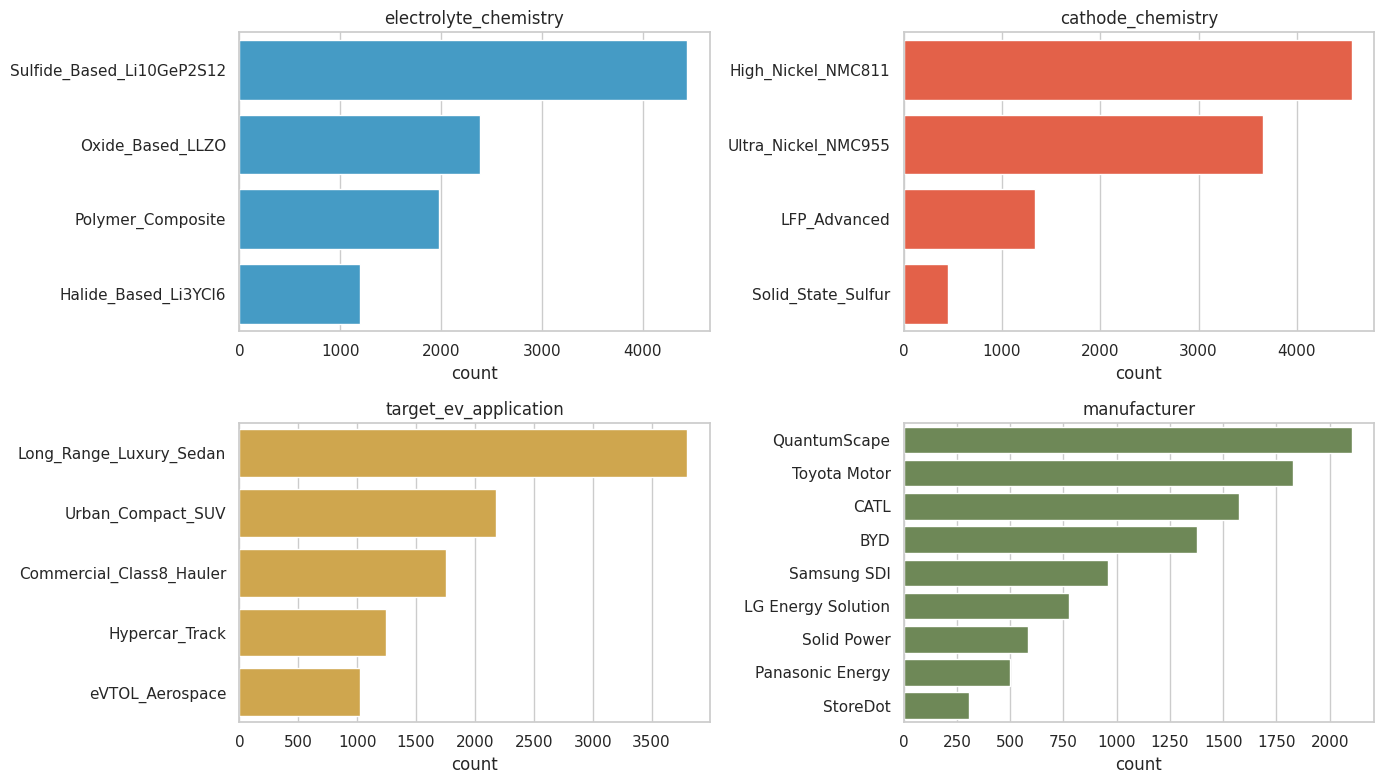

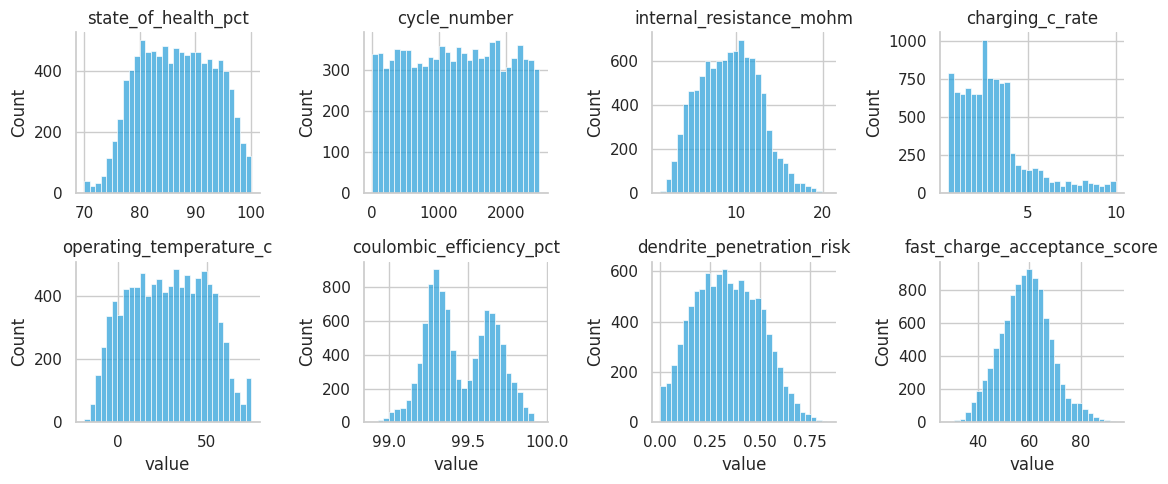

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
specs = [
    (axes[0, 0], "electrolyte_chemistry", "#30a2da"),
    (axes[0, 1], "cathode_chemistry", "#fc4f30"),
    (axes[1, 0], "target_ev_application", "#e5ae38"),
    (axes[1, 1], "manufacturer", "#6d904f"),
]
for ax, col, color in specs:
    order = df[col].value_counts().index.tolist()
    sns.countplot(data=df, y=col, order=order, color=color, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

num_panel = [
    "state_of_health_pct", "cycle_number", "internal_resistance_mohm",
    "charging_c_rate", "operating_temperature_c", "coulombic_efficiency_pct",
    "dendrite_penetration_risk", "fast_charge_acceptance_score",
]
melt = df[num_panel].melt(var_name="feature", value_name="value")
g = sns.FacetGrid(
    melt, col="feature", col_wrap=4, sharex=False, sharey=False, height=2.5, aspect=1.15,
)
g.map_dataframe(sns.histplot, x="value", bins=30, color="#30a2da")
g.set_titles("{col_name}")
plt.show()

**Interpretation** <br>
Sulfide electrolyte and high-nickel cathodes are the common chemistries. Long-range luxury sedan is the largest application (about 3,800 cells); hypercar and eVTOL are the smaller duty cycles. QuantumScape, Toyota, CATL, and BYD lead the manufacturer counts.

Health, cycles, resistance, and temperature are spread across their ranges. Coulombic efficiency is a narrow peak. Charge rate has a long upper tail, which is where the hypercar rows sit.

# **4. Chemistry, Readiness, and Duty:** <a id="Chemistry"></a>

Median SOH by electrolyte × cathode


,electrolyte_chemistry,cathode_chemistry,cells,median_soh,median_cycles
13,Sulfide_Based_Li10GeP2S12,Ultra_Nickel_NMC955,"2,009",86.40,1278
10,Sulfide_Based_Li10GeP2S12,High_Nickel_NMC811,"2,001",86.70,1223
5,Oxide_Based_LLZO,Ultra_Nickel_NMC955,"1,418",86.63,1262
6,Polymer_Composite,High_Nickel_NMC811,"1,015",86.92,1217
4,Oxide_Based_LLZO,High_Nickel_NMC811,967,87.26,1193
7,Polymer_Composite,LFP_Advanced,600,86.06,1324
0,Halide_Based_Li3YCl6,High_Nickel_NMC811,574,86.37,1276
1,Halide_Based_Li3YCl6,LFP_Advanced,388,87.12,1231
11,Sulfide_Based_Li10GeP2S12,LFP_Advanced,343,86.45,1328
8,Polymer_Composite,Solid_State_Sulfur,222,85.99,1314


Duty cycle by application


,target_ev_application,cells,median_soh,median_cycles,median_temp,median_c_rate,median_dendrite
1,Hypercar_Track,"1,242",83.77,1172,43.5,6.95,0.433
4,eVTOL_Aerospace,"1,024",85.91,1251,34.5,4.20,0.357
3,Urban_Compact_SUV,"2,177",87.05,1278,23.1,2.20,0.312
0,Commercial_Class8_Hauler,"1,754",87.12,1262,24.7,2.30,0.315
2,Long_Range_Luxury_Sedan,"3,803",87.14,1262,24.5,2.30,0.308


Readiness


,commercial_readiness_level,cells,median_soh,median_cycles
0,TRL_6_Laboratory_Prototype,"1,321",92.67,624
1,TRL_7_Automotive_Testing,"1,464",86.30,1282
2,TRL_8_Pilot_Production,"5,727",86.49,1241
3,TRL_9_Commercial_Fleet,"1,488",82.27,1819


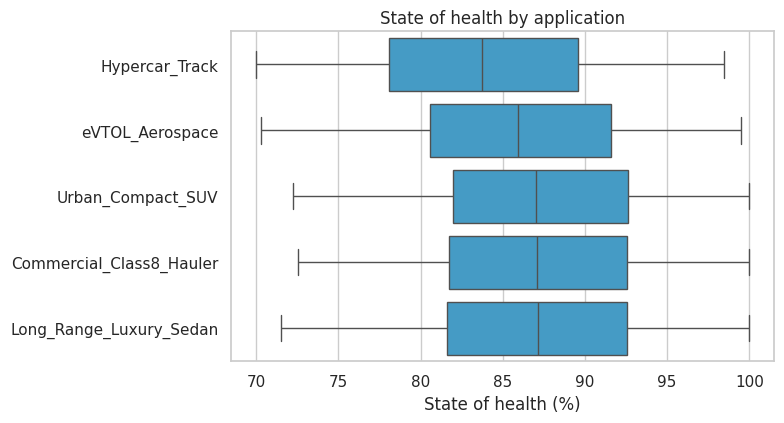

In [5]:
chem = (
    df.groupby(["electrolyte_chemistry", "cathode_chemistry"], as_index=False)
    .agg(
        cells=("cell_id", "size"),
        median_soh=("state_of_health_pct", "median"),
        median_cycles=("cycle_number", "median"),
    )
    .sort_values("cells", ascending=False)
)
print("Median SOH by electrolyte × cathode")
display(
    chem.style.format({
        "cells": "{:,.0f}",
        "median_soh": "{:.2f}",
        "median_cycles": "{:.0f}",
    }).background_gradient(subset=["median_soh"], cmap="YlGn")
)

app = (
    df.groupby("target_ev_application", as_index=False)
    .agg(
        cells=("cell_id", "size"),
        median_soh=("state_of_health_pct", "median"),
        median_cycles=("cycle_number", "median"),
        median_temp=("operating_temperature_c", "median"),
        median_c_rate=("charging_c_rate", "median"),
        median_dendrite=("dendrite_penetration_risk", "median"),
    )
    .sort_values("median_soh")
)
print("Duty cycle by application")
display(
    app.style.format({
        "cells": "{:,.0f}",
        "median_soh": "{:.2f}",
        "median_cycles": "{:.0f}",
        "median_temp": "{:.1f}",
        "median_c_rate": "{:.2f}",
        "median_dendrite": "{:.3f}",
    }).background_gradient(subset=["median_soh"], cmap="YlGn")
)

trl = (
    df.groupby("commercial_readiness_level", observed=True, as_index=False)
    .agg(
        cells=("cell_id", "size"),
        median_soh=("state_of_health_pct", "median"),
        median_cycles=("cycle_number", "median"),
    )
)
print("Readiness")
display(trl.style.format({"cells": "{:,.0f}", "median_soh": "{:.2f}", "median_cycles": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4.4))
sns.boxplot(
    data=df, y="target_ev_application", x="state_of_health_pct",
    order=app["target_ev_application"].tolist(), color="#30a2da", ax=ax,
)
ax.set_title("State of health by application")
ax.set_ylabel("")
ax.set_xlabel("State of health (%)")
plt.tight_layout()
plt.show()

**Interpretation** <br>
Chemistry combinations share a median SOH near 86. The electrolyte × cathode table does not separate health.

Application does. Hypercar cells have median SOH 83.8 at median 1,172 cycles, while the long-range sedan is 87.1 at 1,262 cycles. The hypercar median temperature is 43.6°C and the median charge rate is 6.95C, against about 24°C and 2.3C for the sedan and the class-8 hauler. eVTOL sits between them.

Readiness follows cycles. TRL 6 prototypes have median 624 cycles and median SOH 92.7. TRL 9 fleet cells have median 1,819 cycles and median SOH 82.3. Pilot production (TRL 8) is the bulk of the file, 5,727 cells.

# **5. Degradation Labels:** <a id="Tiers"></a>

SOH range inside each degradation tier


,cells,soh_min,soh_median,soh_max,median_cycles
degradation_risk_tier,,,,,
Minimal_Degradation_Tier_1,"2,278",92.01,95.10,100.00,344
Moderate_Degradation_Tier_2,"2,282",85.02,88.80,92.00,1057
Accelerated_Degradation_Tier_3,"3,758",78.00,82.77,99.21,1708
Critical_Thermal_Risk_Tier_4,"1,682",70.00,77.48,100.00,2170


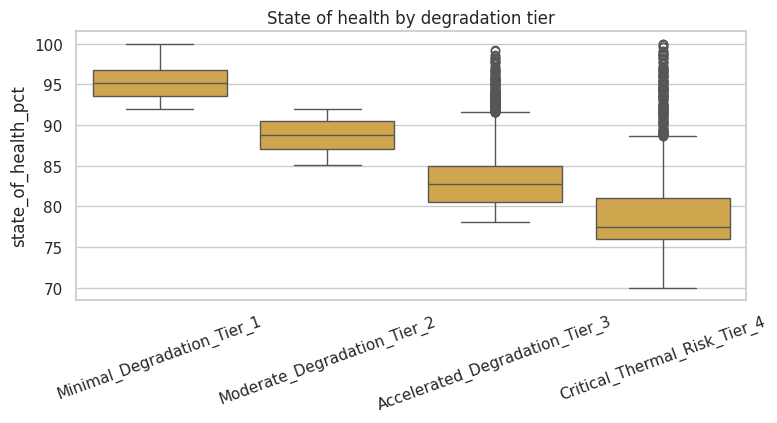

In [6]:
tier = (
    df.groupby("degradation_risk_tier", observed=True)
    .agg(
        cells=("cell_id", "size"),
        soh_min=("state_of_health_pct", "min"),
        soh_median=("state_of_health_pct", "median"),
        soh_max=("state_of_health_pct", "max"),
        median_cycles=("cycle_number", "median"),
    )
)
print("SOH range inside each degradation tier")
display(
    tier.style.format({
        "cells": "{:,.0f}",
        "soh_min": "{:.2f}",
        "soh_median": "{:.2f}",
        "soh_max": "{:.2f}",
        "median_cycles": "{:.0f}",
    }).background_gradient(subset=["soh_median"], cmap="YlGn")
)

fig, ax = plt.subplots(figsize=(8, 4.4))
sns.boxplot(
    data=df, x="degradation_risk_tier", y="state_of_health_pct",
    order=TIER_ORDER, color="#e5ae38", ax=ax,
)
ax.set_title("State of health by degradation tier")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Interpretation** <br>
Tier medians step down the health scale: 95.1, 88.8, 82.8, 77.5. The ranges overlap. Critical thermal risk still reaches 100, and accelerated degradation still reaches the high 90s. The tier is a label with a health gradient. It is not a partition of the SOH axis, so the model below does not use the tier to predict SOH.

# **6. Correlations:** <a id="Correlations"></a>

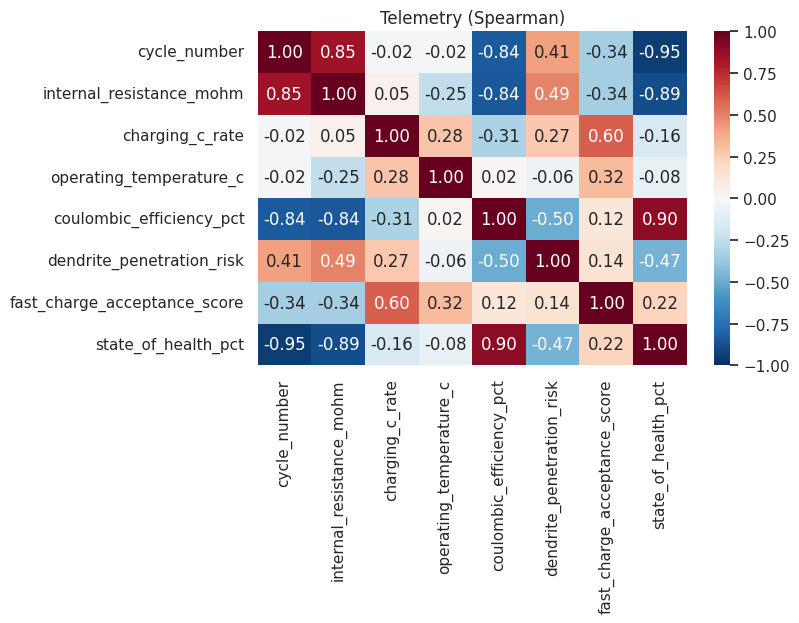

,rho_vs_soh,p_value
feature,,
cycle_number,-0.9487,0.0
internal_resistance_mohm,-0.8887,0.0
coulombic_efficiency_pct,0.8957,0.0
dendrite_penetration_risk,-0.4705,0.0
charging_c_rate,-0.1634,0.0
operating_temperature_c,-0.0806,0.0


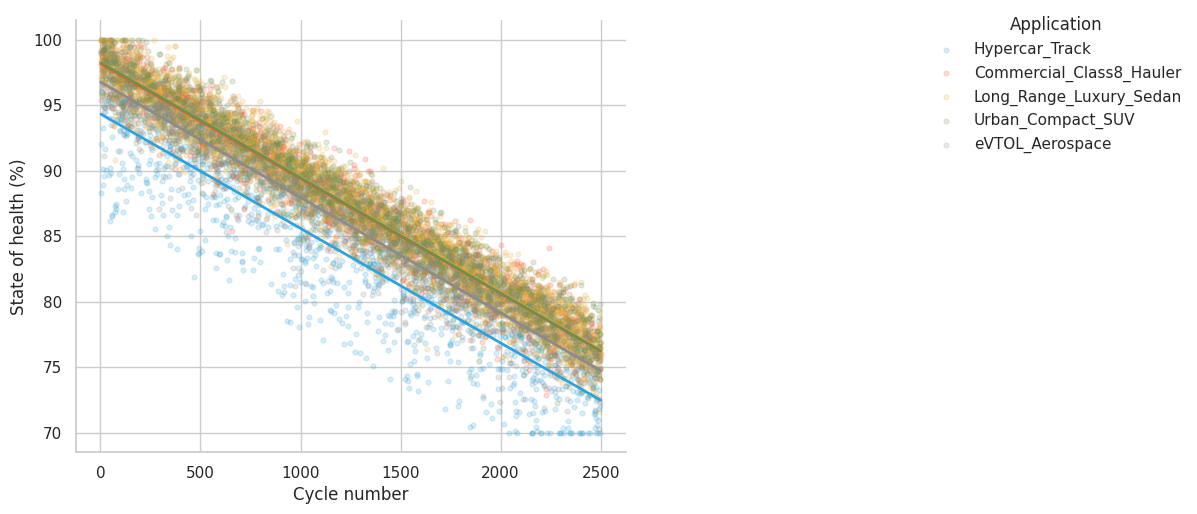

In [7]:
num = [
    "cycle_number", "internal_resistance_mohm", "charging_c_rate",
    "operating_temperature_c", "coulombic_efficiency_pct",
    "dendrite_penetration_risk", "fast_charge_acceptance_score",
    "state_of_health_pct",
]
fig, ax = plt.subplots(figsize=(8.2, 6.4))
sns.heatmap(
    df[num].corr(method="spearman"), annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
)
ax.set_title("Telemetry (Spearman)")
plt.tight_layout()
plt.show()

focus = ["cycle_number", "internal_resistance_mohm", "coulombic_efficiency_pct",
         "dendrite_penetration_risk", "charging_c_rate", "operating_temperature_c"]
rows = []
for col in focus:
    rho, p_value = stats.spearmanr(df[col], df["state_of_health_pct"])
    rows.append({"feature": col, "rho_vs_soh": rho, "p_value": p_value})
display(pd.DataFrame(rows).set_index("feature").round(4))

g = sns.lmplot(
    data=df,
    x="cycle_number",
    y="state_of_health_pct",
    hue="target_ev_application",
    height=5.2,
    aspect=1.3,
    ci=None,
    scatter_kws={"alpha": 0.18, "s": 12},
    line_kws={"lw": 2},
)
g.set_axis_labels("Cycle number", "State of health (%)")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Application", frameon=False)
plt.show()

**Interpretation** <br>
Cycle count and SOH move almost in lockstep (Spearman ρ −0.949). Internal resistance is close behind (ρ −0.889), and coulombic efficiency moves with health (ρ 0.896). Charge rate (ρ −0.163) and operating temperature (ρ −0.081) are weaker rank correlations on their own.

The application lines on the scatter have the same downward slope. Hypercar points sit slightly below the sedan cloud at a similar cycle count, which matches the median gap in the duty-cycle table.

# **7. What Tracks State of Health:** <a id="Model"></a>

                                     model  holdout_r2
                               cycles only       0.888
            cycles + electrolyte + cathode       0.888
                      cycles + application       0.924
cycles + resistance + C-rate + temperature       0.976
                   telemetry + application       0.976
Cycles-only slope: -0.0087 SOH points per cycle; intercept 97.57
Predicted SOH at 0 cycles: 97.6; at 2,000 cycles: 80.1


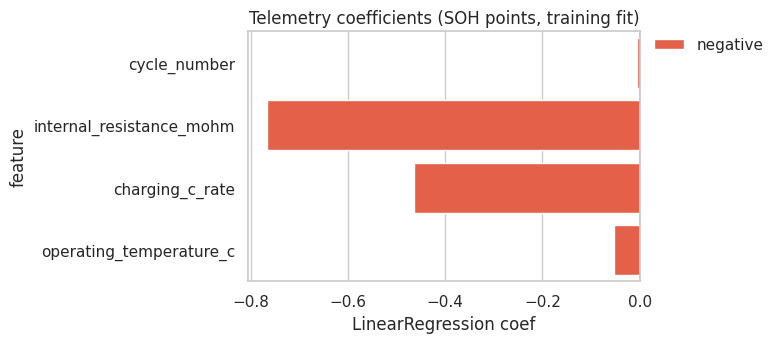

,coef
cycle_number,-0.0058
internal_resistance_mohm,-0.7667
charging_c_rate,-0.4646
operating_temperature_c,-0.0531


In [8]:
# Hold-out R^2 for nested linear models of SOH. Coefficients on the telemetry model are in SOH points.
y = df["state_of_health_pct"]
idx_train, idx_test = train_test_split(df.index, test_size=0.25, random_state=7)
train, test = df.loc[idx_train], df.loc[idx_test]


def holdout_r2(num_cols: list[str], cat_cols: list[str]) -> float:
    transformers = []
    if num_cols:
        transformers.append(("num", "passthrough", num_cols))
    if cat_cols:
        transformers.append(("cat", OneHotEncoder(drop="first"), cat_cols))
    pipe = Pipeline([
        ("pre", ColumnTransformer(transformers)),
        ("lr", LinearRegression()),
    ])
    cols = num_cols + cat_cols
    pipe.fit(train[cols], train["state_of_health_pct"])
    return float(r2_score(test["state_of_health_pct"], pipe.predict(test[cols])))


specs = [
    ("cycles only", ["cycle_number"], []),
    ("cycles + electrolyte + cathode", ["cycle_number"], ["electrolyte_chemistry", "cathode_chemistry"]),
    ("cycles + application", ["cycle_number"], ["target_ev_application"]),
    ("cycles + resistance + C-rate + temperature",
     ["cycle_number", "internal_resistance_mohm", "charging_c_rate", "operating_temperature_c"], []),
    ("telemetry + application",
     ["cycle_number", "internal_resistance_mohm", "charging_c_rate", "operating_temperature_c"],
     ["target_ev_application"]),
]
scores = pd.DataFrame(
    [{"model": name, "holdout_r2": holdout_r2(num_cols, cat_cols)} for name, num_cols, cat_cols in specs]
)
print(scores.round(3).to_string(index=False))

cycle_only = LinearRegression().fit(train[["cycle_number"]], train["state_of_health_pct"])
print(
    f"Cycles-only slope: {cycle_only.coef_[0]:.4f} SOH points per cycle; "
    f"intercept {cycle_only.intercept_:.2f}"
)
print(
    f"Predicted SOH at 0 cycles: {cycle_only.intercept_:.1f}; "
    f"at 2,000 cycles: {cycle_only.intercept_ + 2000 * cycle_only.coef_[0]:.1f}"
)

tele_num = ["cycle_number", "internal_resistance_mohm", "charging_c_rate", "operating_temperature_c"]
tele = LinearRegression().fit(train[tele_num], train["state_of_health_pct"])
tele_coef = pd.Series(tele.coef_, index=tele_num)
fig, ax = plt.subplots(figsize=(8, 3.6))
plot_df = tele_coef.rename("coef").rename_axis("feature").reset_index()
plot_df["sign"] = np.where(plot_df["coef"] >= 0, "positive", "negative")
sns.barplot(
    data=plot_df, x="coef", y="feature", hue="sign", dodge=False,
    palette={"positive": "#30a2da", "negative": "#fc4f30"}, ax=ax,
)
ax.axvline(0, color="black", lw=1)
park_legend(ax)
ax.set_title("Telemetry coefficients (SOH points, training fit)")
ax.set_xlabel("LinearRegression coef")
plt.tight_layout()
plt.show()
display(tele_coef.round(4).rename("coef").to_frame())

**Interpretation** <br>
Cycles alone reach a hold-out R² of 0.888. The training slope is about −0.0087 SOH points per cycle: the line sits near 98 at cycle 0 and near 80 at 2,000 cycles.

Adding electrolyte and cathode leaves the hold-out R² at 0.888. Chemistry labels do not move health once cycles are in the model. Adding the application label lifts R² to 0.924, which is the hypercar and eVTOL duty cycle seen above.

Cycles, resistance, charge rate, and operating temperature together reach 0.976. Putting the application label on top of those four leaves R² at 0.976. The duty-cycle gap is carried by the telemetry the label stands for: hotter operation and a higher charge rate, on top of the cycle count.

# **8. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
10,000 solid-state cells, one row each, 29 complete fields. Manufacturers, electrolytes, cathodes, anodes, and five EV applications are labels on the cell. The rationale text does not repeat.

**Working takeaways:** <br>
- State of health has median 86.7 and a floor of 70. Median cycle count is 1,256.
- Cycle count is the health tracker (Spearman ρ −0.949; hold-out R² 0.888; about −0.0087 SOH points per cycle). Resistance (ρ −0.889) and coulombic efficiency (ρ 0.896) move with it.
- Electrolyte × cathode medians all sit near 86. Adding those labels to cycles does not change hold-out R².
- Hypercar cells are the low-SOH application (median 83.8) at a similar cycle count to the sedan, with median temperature 43.6°C and median charge rate 6.95C. Application plus cycles reaches R² 0.924.
- The four telemetry fields — cycles, resistance, charge rate, temperature — reach hold-out R² 0.976, and the application label adds nothing further.
- Degradation-tier medians step 95.1 → 88.8 → 82.8 → 77.5, and the ranges overlap. TRL 9 cells have more cycles and lower SOH than TRL 6 cells.

**Open follow-ups:** <br>
- Separate calendar age from cycle count if a later file carries both. This table's health gradient is the cycle axis.
- Treat the unique rationale string as a note for a single cell, not as a feature with levels.